# V11: confidence calibration from later human votes

Goal: rank19 or better on the actual Kaggle leaderboard. The last verified official
result is0.83053/rank30; local evidence does not complete that goal.

Gemma2-9B original and ArmoRM/Llama3-8B swapped retain equal weights,4096conversation
cap and8192packing. The only fitted parameter is one shared temperature:
$q_k=p_k^{1/T}/\sum_j p_j^{1/T}$, with $T\in[0.5,2]$.
Larger T reduces confidence. It preserves the predicted class and therefore accuracy.
No expert weight, tie offset, route or model identity is learned.

Source: official Arena140k revision6322995ab34d7c2693e3f47dd13fa5caa0789a74.
Later votes are independent-source out-of-time evidence, not competition CV.
New model populations and class priors may differ despite length matching.

,source_rows,eligible_rows,prompt_session_groups,selected_groups,CPU_seconds,peak_RSS_GB,CPU_GPU_token_identity
0,135634,49118,45703,2048,108.358345,1.083515,True


Selected vote dates: ['2025-04-17T03:51:30.343572+00:00', '2025-07-24T23:39:24.483169+00:00']
Selection used targets: False
Private labels are not loaded by this notebook.


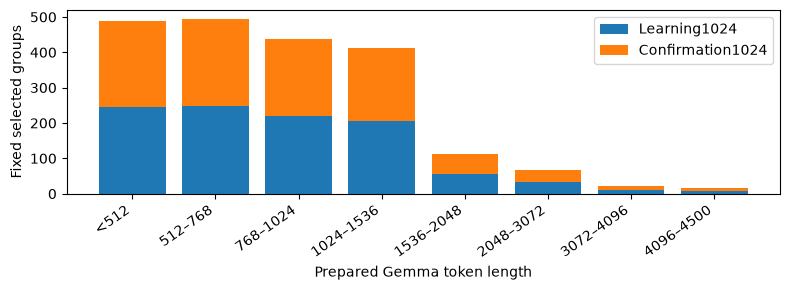

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_011'
def read(name):return json.loads((PUB/name).read_text())
cohort=read('cohort_manifest.json');phase=read('span_plan.json')
display(pd.DataFrame([{'source_rows':cohort['counts']['source_rows'],'eligible_rows':cohort['counts']['eligible_rows'],
 'prompt_session_groups':cohort['counts']['unique_groups'],'selected_groups':cohort['rows'],
 'CPU_seconds':cohort['elapsed_seconds'],'peak_RSS_GB':cohort['peak_rss_bytes']/1e9,
 'CPU_GPU_token_identity':cohort['cpu_gpu_token_identity']}]))
print('Selected vote dates:',cohort['selected_timestamp_range'])
print('Selection used targets:',cohort['uses_targets_for_selection'])
print('Private labels are not loaded by this notebook.')
fig,ax=plt.subplots(figsize=(8,3))
x=np.arange(8);ax.bar(x,cohort['learning_bin_counts'],label='Learning1024')
ax.bar(x,cohort['confirmation_bin_counts'],bottom=cohort['learning_bin_counts'],label='Confirmation1024')
ax.set_xticks(x,['<512','512–768','768–1024','1024–1536','1536–2048','2048–3072','3072–4096','4096–4500'],rotation=35,ha='right')
ax.set_ylabel('Fixed selected groups');ax.set_xlabel('Prepared Gemma token length');ax.legend();fig.tight_layout();plt.show()

The original256row controls must reproduce raw component predictions within1e-5.
A disjoint original512row random sample measures target runtime;64long rows stress
context and memory. The conservative25krow projection includes20%margin, all cold
and warmup costs and600seconds reserve, and must be below32400seconds.
Neither the training-overlapping controls nor runtime cohorts estimate independent
quality. Each remote mutation has an immutable intent and exact version receipt.

In [2]:
jobs=[]
for role in ['calibration_learning','calibration_confirmation']:
 path=PUB/'jobs'/role/'status.json'
 if path.exists():
  status=json.loads(path.read_text());jobs.append({'role':role,**status})
display(pd.DataFrame(jobs))
live=[]
for role in ['calibration_learning','calibration_confirmation']:
 path=PUB/'jobs'/role/'progress.json'
 if path.exists():
  p=json.loads(path.read_text());live.append({'job':role,'observed_at':p['observed_at'],**p['latest']})
display(pd.DataFrame(live))
checks=[]
for role in ['calibration_learning','calibration_confirmation']:
 path=PUB/(role+'_qualification.json')
 if path.exists():
  q=json.loads(path.read_text());checks.append({'role':role,'controls_passed':q['all_controls_passed'],
   'max_raw_control_difference':max(v['max_abs_probability_difference'] for v in q['control_identity'].values()),
   'two_T4_verified':q['both_t4_verified'],'hidden_projection_hours':q['runtime']['projection_seconds']/3600,
   'runtime_passed':q['runtime_gate_passed']})
display(pd.DataFrame(checks))
print('Public budget hours:',phase['gpu_session_seconds_cap']/3600,'; fixed deadline:',phase['deadline'])
print('Initial pilot conservative forecast minutes:',phase['learning_forecast_seconds']/60)

,role,status,kernel_version,observed_at
0,calibration_learning,COMPLETE,arseniytrushin/llm-preference-span011-learning...,2026-11-07T11:37:02.527347+00:00


,job,observed_at,stage,complete
0,calibration_learning,2026-11-07T11:36:16.389877+00:00,complete,True


,role,controls_passed,max_raw_control_difference,two_T4_verified,hidden_projection_hours,runtime_passed
0,calibration_learning,True,0.0,True,8.291514,True


Public budget hours: 6.0 ; fixed deadline: 2026-11-09T10:32:36.230293+00:00
Initial pilot conservative forecast minutes: 57.542545313892944


Learning uses five group folds to estimate a single-temperature procedure.
Positive cross-fitted gain is only permission to collect confirmation evidence.
The temperature fitted on all learning groups must be frozen before the separate
confirmation pass. Confirmation needs loss reduction≥0.001 and paired group95%
lower bound>0, followed by class/length/domain review and engineering checks.
The confirmation pass never fits a parameter. Official leaderboard feedback is
never used to fit T. Missing metrics below mean the stage is still incomplete.

,stage,design,T,base_log_loss,candidate_log_loss,gain,paired_group95,accuracy,argmax_preserved,information_gate_passed
0,learning,Learning group-cross-fitted temperatures,1.316152,1.024173,1.019558,0.004616,"[-0.002451, 0.0124]",0.486328,True,True


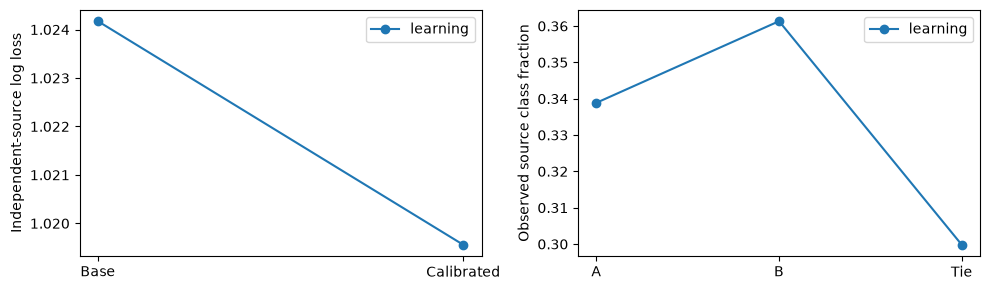

In [3]:
metrics=[];records={}
for stage in ['learning','confirmation']:
 path=PUB/(stage+'_metrics.json')
 if path.exists():
  q=json.loads(path.read_text());records[stage]=q;c=q['comparison']
  metrics.append({'stage':stage,'design':q['quality_design'],'T':q['temperature'],
   'base_log_loss':c['baseline_log_loss'],'candidate_log_loss':c['candidate_log_loss'],
   'gain':c['loss_reduction'],'paired_group95':c['paired_group95'],'accuracy':c['candidate_accuracy'],
   'argmax_preserved':c['argmax_preserved'],'information_gate_passed':q['information_gate_passed']})
display(pd.DataFrame(metrics))
if records:
 fig,axes=plt.subplots(1,2,figsize=(10,3))
 for name,q in records.items():
  c=q['comparison'];axes[0].plot([0,1],[c['baseline_log_loss'],c['candidate_log_loss']],marker='o',label=name)
  axes[1].plot(range(3),q['diagnostics']['observed_class_fractions'],marker='o',label=name)
 axes[0].set_xticks([0,1],['Base','Calibrated']);axes[0].set_ylabel('Independent-source log loss')
 axes[1].set_xticks(range(3),['A','B','Tie']);axes[1].set_ylabel('Observed source class fraction')
 axes[0].legend();axes[1].legend();fig.tight_layout();plt.show()
else:print('Source scoring/quality analysis pending; no fitted or confirmed gain yet.')

In [4]:
for stage,q in records.items():
 print(stage,q['diagnostics']['transfer_limits'])
 display(pd.DataFrame(q['comparison']['class_log_loss']).T)
 rows={k:v for k,v in q['diagnostics'].items() if k.startswith('length_bin_') or k in ['code_keyword_proxy','other_prompts']}
 display(pd.DataFrame(rows).T)
print('Goal completion requires a fresh complete official observation at rank<=19.')

learning English first-evaluation single-turn later votes, length-matched to original population. New model population and class prior may differ. Code keyword is a diagnostic proxy only. Not competition CV.


,rows,base,candidate
0,347.0,1.000147,1.003270
1,370.0,0.961840,0.970039
2,307.0,1.126455,1.097648


,rows,baseline_log_loss,candidate_log_loss,loss_reduction
length_bin_0,244.0,1.052942,1.039034,0.013908
length_bin_1,248.0,1.007251,1.006013,0.001238
length_bin_2,219.0,1.059230,1.045241,0.013989
length_bin_3,207.0,0.952695,0.967710,-0.015014
length_bin_4,55.0,1.062193,1.048299,0.013894
length_bin_5,33.0,1.061718,1.056948,0.004770
length_bin_6,11.0,1.156248,1.126797,0.029451
length_bin_7,7.0,0.954563,0.979612,-0.025048
code_keyword_proxy,56.0,1.080169,1.075417,0.004752
other_prompts,968.0,1.020934,1.016326,0.004608


Goal completion requires a fresh complete official observation at rank<=19.
